# Euler-metoden

Gitt differensialligningen $\frac{dy}{dt}=f(t,y)$ med startbetingelsen $y(t_0)=y_0,$ kan Euler-metoden brukes til å beregne en tilnærmet løsning ved diskrete tidspunkter. For et tidssteg $h$ beregnes neste verdi som

$$
y_{n+1}=y_n+h\,f(t_n,y_n).
$$

Tidspunktet oppdateres samtidig som

$$
t_{n+1}=t_n+h.
$$



## Algoritme

1. Start med kjente verdier $t_0$ og $y_0$.
2. Beregn stigningstallet:

   $
   f(t_n,y_n)
   $

3. Beregn neste verdi:

   $
   y_{n+1}=y_n+h\,f(t_n,y_n)
   $

4. Gjenta prosessen for hvert tidssteg.




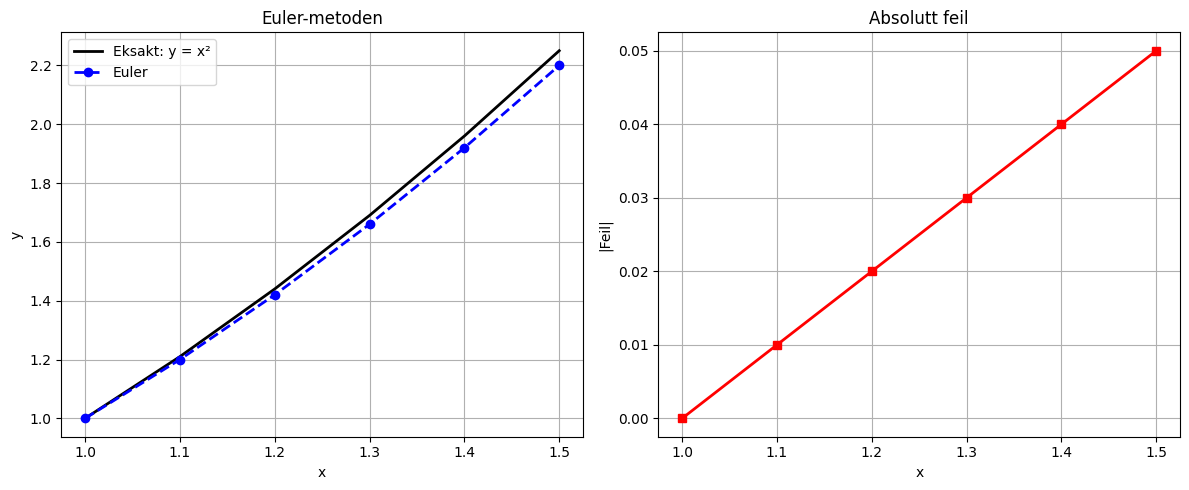

 n    x      Euler     Eksakt     Feil
----------------------------------------
 0   1.0     1.00      1.00     0.00
 1   1.1     1.20      1.21     0.01
 2   1.2     1.42      1.44     0.02
 3   1.3     1.66      1.69     0.03
 4   1.4     1.92      1.96     0.04
 5   1.5     2.20      2.25     0.05


In [12]:
# TEST CELL
import numpy as np
import matplotlib.pyplot as plt

# Data fra tabellen

x = np.array([1.0, 1.1, 1.2, 1.3, 1.4, 1.5])

y_euler = np.array([
    1.00,
    1.20,
    1.42,
    1.66,
    1.92,
    2.20
])

y_exact = x**2

error = np.abs(y_exact - y_euler)

# To plott side om side
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# ------------------------
# Plot 1: Euler vs eksakt
# ------------------------
ax[0].plot(
    x,
    y_exact,
    'k-',
    linewidth=2,
    label='Eksakt: y = x²'
)

ax[0].plot(
    x,
    y_euler,
    'bo--',
    linewidth=2,
    markersize=6,
    label='Euler'
)

ax[0].set_title('Euler-metoden')
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].grid(True)
ax[0].legend()

# ------------------------
# Plot 2: Feil
# ------------------------
ax[1].plot(
    x,
    error,
    'rs-',
    linewidth=2,
    markersize=6
)

ax[1].set_title('Absolutt feil')
ax[1].set_xlabel('x')
ax[1].set_ylabel('|Feil|')
ax[1].grid(True)

plt.tight_layout()
plt.show()

# Skriv ut tabellen
print(" n    x      Euler     Eksakt     Feil")
print("----------------------------------------")

for n in range(len(x)):
    print(
        f"{n:2d}  "
        f"{x[n]:4.1f}   "
        f"{y_euler[n]:6.2f}    "
        f"{y_exact[n]:6.2f}    "
        f"{error[n]:5.2f}"
    )

## Euler-metoden med eksakt verdi

Gitt

$$
\frac{dy}{dx}=2x
$$

med startbetingelse

$$
y(1)=1
$$

og steglengde

$$
h=0.1.
$$

Euler-formelen er

$$
y_{n+1}=y_n+h\,f(x_n)
$$

der

$$
f(x)=2x.
$$

| n | x_n | y_n (Euler) | Utregning | Eksakt verdi y(x_n)=x_n² | Feil |
|---:|---:|---:|---|---:|---:|
| 0 | 1.0 | 1.00 | Startverdi | 1.00 | 0.00 |
| 1 | 1.1 | 1.20 | y₁ = 1.00 + 0.1·(2·1.0) = 1.20 | 1.21 | 0.01 |
| 2 | 1.2 | 1.42 | y₂ = 1.20 + 0.1·(2·1.1) = 1.42 | 1.44 | 0.02 |
| 3 | 1.3 | 1.66 | y₃ = 1.42 + 0.1·(2·1.2) = 1.66 | 1.69 | 0.03 |
| 4 | 1.4 | 1.92 | y₄ = 1.66 + 0.1·(2·1.3) = 1.92 | 1.96 | 0.04 |
| 5 | 1.5 | 2.20 | y₅ = 1.92 + 0.1·(2·1.4) = 2.20 | 2.25 | 0.05 |

### Resultat

Euler-metoden gir

$$
y(1.5)\approx 2.20
$$

mens den eksakte løsningen er

$$
y(1.5)=2.25.
$$

Feilen blir

$$
e=2.25-2.20=0.05.
$$

# Euler-metoden for svingligningen

Euler-metoden for svingligningen er en modifisert Euler-metode (midpoint- eller leapfrog-formulering) anvendt på svingligningen.

Svingligningen kan skrives som

$$
\frac{d^2\delta}{dt^2}
=
\frac{\pi f}{H}P_a.
$$

Vi innfører vinkelhastigheten

$$
\omega=\frac{d\delta}{dt},
$$

slik at ligningen splittes i to førsteordens differensialligninger:

$$
\frac{d\delta}{dt}
=
\omega
$$

og

$$
\frac{d\omega}{dt}
=
\frac{\pi f}{H}P_a.
$$

## Oppdatering

Euler-metoden gir da oppdateringene

$$
\omega_{n+1}
=
\omega_n
+
h\frac{\pi f}{H}P_{a,n}
$$

og

$$
\delta_{n+1}
=
\delta_n+h\omega_n.
$$

Her er:

- $\delta_n$ rotorvinkelen ved tidspunkt $t_n$
- $\omega_n$ hastighetsavviket ved tidspunkt $t_n$
- $P_{a,n}$ akselerasjonseffekten ved tidspunkt $t_n$
- $h$ tidssteget

Disse ligningene brukes iterativt for å beregne rotorvinkel og hastighet gjennom en transient.

---

# Euler-metoden (punkt-for-punkt-metoden)

I denne metoden bestemmes endringen i rotorvinkelen over korte tidsintervaller.

Følgende antakelser gjøres:

1. Den akselererende effekten $\Delta P$ ved begynnelsen av et tidsintervall antas konstant fra midten av forrige intervall til midten av det aktuelle intervallet.

2. Vinkelhastigheten $\omega$ antas konstant gjennom hele tidsintervallet og beregnes for midtpunktet av intervallet.

---

## Endring i vinkelhastighet

Fra svingligningen

$$
M\frac{d^2\delta}{dt^2}
=
\Delta P
$$

fås

$$
\frac{d^2\delta}{dt^2}
=
\frac{\Delta P}{M}.
$$

Over tidsintervallet $\Delta t$ blir endringen i vinkelhastighet

$$
\omega_{n-\frac12}
-
\omega_{n-\frac32}
=
\frac{\Delta P_{n-1}}{M}\Delta t.
$$

eller

$$
\Delta\omega_{n-\frac12}
=
\frac{\Delta P_{n-1}}{M}\Delta t.
$$

Dette uttrykket brukes til å oppdatere rotorens hastighet fra ett halvsteg til det neste.

---

## Endring i rotorvinkel

Rotorvinkelens endring i intervallet fra tid $(n-2)$ til $(n-1)$ er

$$
\delta_{n-1}-\delta_{n-2}
=
\Delta\delta_{n-1}.
$$

Siden $\omega_{n-\frac12}$ antas konstant gjennom intervallet,

$$
\omega_{n-\frac12}
=
\frac{\Delta\delta_{n-1}}{\Delta t}.
$$

Dermed fås

$$
\Delta\delta_{n-1}
=
\omega_{n-\frac12}\Delta t
$$

og

$$
\delta_{n-1}
=
\delta_{n-2}
+
\omega_{n-\frac12}\Delta t.
$$

---

# Numerisk algoritme

For hvert tidssteg utføres følgende beregninger.

## 1. Beregn akselererende effekt

$$
\Delta P_n
=
P_m-P_e(\delta_n).
$$

## 2. Oppdater vinkelhastigheten

$$
\omega_{n+\frac12}
=
\omega_{n-\frac12}
+
\frac{\Delta P_n}{M}\Delta t.
$$

## 3. Oppdater rotorvinkelen

$$
\delta_{n+1}
=
\delta_n
+
\omega_{n+\frac12}\Delta t.
$$

---

Over det $n$-te intervallet er endringen i rotorvinkelen

$$
\Delta\delta_n
=
\delta_n-\delta_{n-1}
=
\omega_{n-\frac12}\Delta t.
$$

Tilsvarende er

$$
\Delta\delta_{n-1}
=
\delta_{n-1}-\delta_{n-2}
=
\omega_{n-\frac32}\Delta t.
$$

Ved å subtrahere disse uttrykkene fås

$$
\Delta\delta_n-\Delta\delta_{n-1}
=
\Delta t
\left(
\omega_{n-\frac12}
-
\omega_{n-\frac32}
\right).
$$

Fra hastighetsoppdateringen har vi

$$
\omega_{n-\frac12}
-
\omega_{n-\frac32}
=
\frac{\Delta P_{n-1}}{M}\Delta t.
$$

Innsetting gir

$$
\Delta\delta_n-\Delta\delta_{n-1}
=
\Delta t
\left(
\frac{\Delta P_{n-1}}{M}\Delta t
\right)
=
\frac{\Delta P_{n-1}}{M}
(\Delta t)^2.
$$

Dermed fås den rekursive ligningen

$$
\boxed{
\Delta\delta_n
=
\Delta\delta_{n-1}
+
\frac{\Delta P_{n-1}}{M}
(\Delta t)^2
}
$$

Dette er grunnligningen for den klassiske punkt-for-punkt-metoden.

Når $\Delta\delta_n$ er funnet, oppdateres rotorvinkelen fra

$$
\boxed{
\delta_n
=
\delta_{n-1}
+
\Delta\delta_n
}
$$

---

# Fysisk betydning

Metoden følger den naturlige årsakskjeden i kraftsystemet

$$
(P_m-P_e)
\rightarrow
\text{akselerasjon}
\rightarrow
\omega
\rightarrow
\delta.
$$

Den mekaniske og elektriske effektubalansen bestemmer rotorens akselerasjon. Akselerasjonen gir en endring i rotorhastigheten, og rotorhastigheten bestemmer deretter hvordan rotorvinkelen utvikler seg med tiden.

Ved å gjenta disse beregningene for små tidsintervaller kan den transiente rotorvinkelresponsen bestemmes numerisk uten å løse svingligningen analytisk.

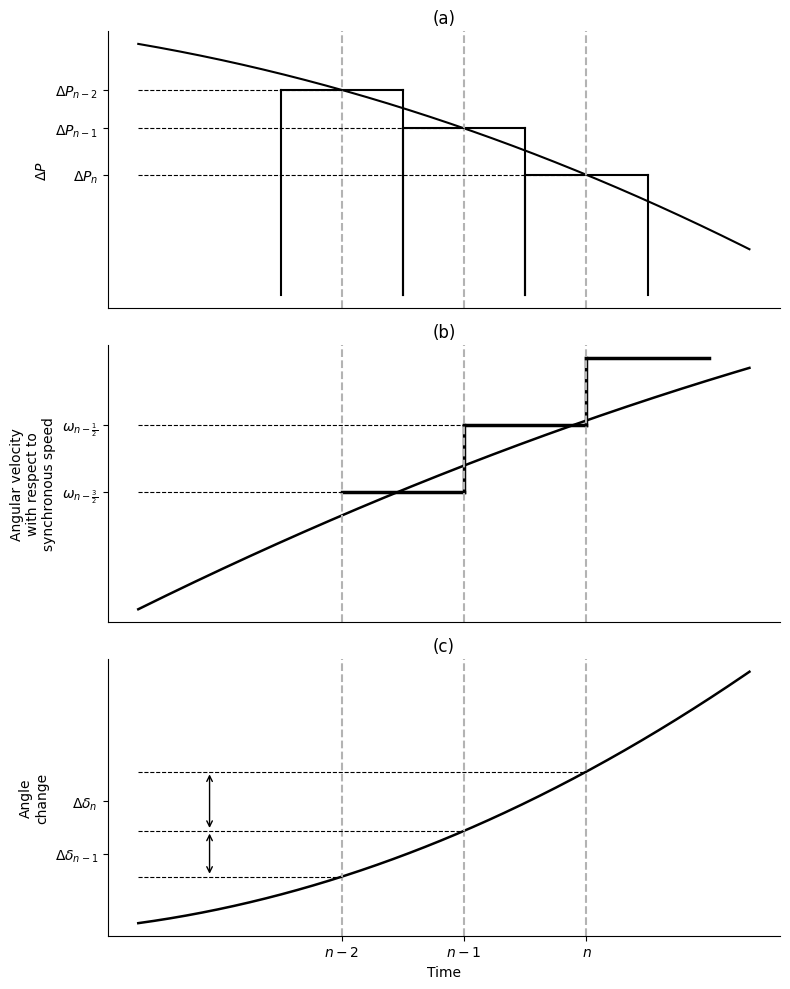

In [8]:
# TEST CELL
import numpy as np
import matplotlib.pyplot as plt

# ======================================================
# Smooth reference curves
# ======================================================

t = np.linspace(0, 3, 500)

dP = 1.8 - 0.25*t - 0.08*t**2
omega = 0.3 + 0.30*t - 0.02*t**2
delta = 0.15 + 0.15*t + 0.10*t**2

# Time locations
t_nm2 = 1.0
t_nm1 = 1.6
t_n = 2.2

dt = t_nm1 - t_nm2

# ======================================================
# Create figure
# ======================================================

fig, ax = plt.subplots(3, 1, figsize=(8, 10))

# ======================================================
# (a) Accelerating power ΔP
# ======================================================

ax[0].plot(t, dP, 'k', lw=1.5)

DP_nm2 = np.interp(t_nm2, t, dP)
DP_nm1 = np.interp(t_nm1, t, dP)
DP_n = np.interp(t_n, t, dP)

for tx, y in zip(
    [t_nm2, t_nm1, t_n],
    [DP_nm2, DP_nm1, DP_n]
):

    width = 0.6

    ax[0].plot(
        [tx - width/2, tx + width/2],
        [y, y],
        'k'
    )

    ax[0].plot(
        [tx - width/2, tx - width/2],
        [0, y],
        'k'
    )

    ax[0].plot(
        [tx + width/2, tx + width/2],
        [0, y],
        'k'
    )

    ax[0].axvline(
        tx,
        color='0.7',
        ls='--'
    )

    ax[0].hlines(
        y,
        0,
        tx,
        colors='k',
        linestyles='--',
        linewidth=0.8
    )

ax[0].set_yticks([DP_nm2, DP_nm1, DP_n])

ax[0].set_yticklabels([
    r'$\Delta P_{n-2}$',
    r'$\Delta P_{n-1}$',
    r'$\Delta P_n$'
])

ax[0].set_ylabel(r'$\Delta P$')
ax[0].set_title('(a)')
ax[0].set_xticks([])

ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

# ======================================================
# (b) Angular velocity ω
# ======================================================

ax[1].plot(t, omega, 'k', lw=1.8)

omega_nm32 = 0.65
omega_nm12 = 0.85
omega_np12 = 1.05

# ω_(n−3/2)

ax[1].plot(
    [t_nm2, t_nm1],
    [omega_nm32, omega_nm32],
    'k',
    lw=2.5
)

# jump at n−1

ax[1].plot(
    [t_nm1, t_nm1],
    [omega_nm32, omega_nm12],
    'k',
    lw=2.5
)

# ω_(n−1/2)

ax[1].plot(
    [t_nm1, t_n],
    [omega_nm12, omega_nm12],
    'k',
    lw=2.5
)

# jump at n

ax[1].plot(
    [t_n, t_n],
    [omega_nm12, omega_np12],
    'k',
    lw=2.5
)

# next interval

ax[1].plot(
    [t_n, t_n + dt],
    [omega_np12, omega_np12],
    'k',
    lw=2.5
)

for tx in [t_nm2, t_nm1, t_n]:

    ax[1].axvline(
        tx,
        color='0.7',
        ls='--'
    )

ax[1].hlines(
    omega_nm32,
    0,
    t_nm1,
    colors='k',
    linestyles='--',
    linewidth=0.8
)

ax[1].hlines(
    omega_nm12,
    0,
    t_n,
    colors='k',
    linestyles='--',
    linewidth=0.8
)

ax[1].set_yticks([
    omega_nm32,
    omega_nm12
])

ax[1].set_yticklabels([
    r'$\omega_{n-\frac{3}{2}}$',
    r'$\omega_{n-\frac{1}{2}}$'
])

ax[1].set_ylabel(
    'Angular velocity\nwith respect to\nsynchronous speed'
)

ax[1].set_title('(b)')
ax[1].set_xticks([])

ax[1].spines['top'].set_visible(False)
ax[1].spines['right'].set_visible(False)

# ======================================================
# (c) Angle change Δδ
# ======================================================

ax[2].plot(t, delta, 'k', lw=1.8)

for tx in [t_nm2, t_nm1, t_n]:

    ax[2].axvline(
        tx,
        color='0.7',
        ls='--'
    )

delta_nm2 = np.interp(t_nm2, t, delta)
delta_nm1 = np.interp(t_nm1, t, delta)
delta_n = np.interp(t_n, t, delta)

ax[2].hlines(
    delta_nm2,
    0,
    t_nm2,
    colors='k',
    linestyles='--',
    linewidth=0.8
)

ax[2].hlines(
    delta_nm1,
    0,
    t_nm1,
    colors='k',
    linestyles='--',
    linewidth=0.8
)

ax[2].hlines(
    delta_n,
    0,
    t_n,
    colors='k',
    linestyles='--',
    linewidth=0.8
)

# Δδ_(n−1)

ax[2].annotate(
    '',
    xy=(0.35, delta_nm1),
    xytext=(0.35, delta_nm2),
    arrowprops=dict(arrowstyle='<->')
)

# Δδ_n

ax[2].annotate(
    '',
    xy=(0.35, delta_n),
    xytext=(0.35, delta_nm1),
    arrowprops=dict(arrowstyle='<->')
)

ax[2].set_yticks([
    (delta_nm2 + delta_nm1) / 2,
    (delta_nm1 + delta_n) / 2
])

ax[2].set_yticklabels([
    r'$\Delta\delta_{n-1}$',
    r'$\Delta\delta_n$'
])

ax[2].set_ylabel('Angle\nchange')
ax[2].set_xlabel('Time')

ax[2].set_xticks([
    t_nm2,
    t_nm1,
    t_n
])

ax[2].set_xticklabels([
    r'$n-2$',
    r'$n-1$',
    r'$n$'
])

ax[2].set_title('(c)')

ax[2].spines['top'].set_visible(False)
ax[2].spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# Fremgangsmåte

- Bestem $\Delta_t$  (Vanligvis 0.05 s.)
- Finn M
- Beregn $\frac{(\Delta_t)^2}{M}$
- Finn normal driftsvinkel; $\delta_0 = sin^{-1}\big(\frac{P_m}{P_max}\big)$
- Finn $\Delta P$, rett etter feilen; $\Delta P = Pm - P_{max,feil} sin \delta_0$ 
- Den første verdien av den akselererende effekten refererer til midten av det foregående intervallet, mens den andre verdien refererer til midten av intervallet som analyseres: Bruk $\Delta P = \frac{\Delta P}{2}$
- Finn ny $\Delta\delta_n$: 

$$\Delta\delta_n= \Delta\delta_{n-1}+\frac{(\Delta_t)^2}{M}\Delta P_{n-1}$$
